# Мини-проект: маятник с трением и штрафом на состояние

Динамика:
$$
\dot\theta=\omega,\qquad
\dot\omega=-\sin\theta-\gamma\omega+u.
$$

Минимизируем
$$
J=20(\theta(T)-\pi)^2+5\omega(T)^2+
\int_0^T\left[q_\theta(\theta-\pi)^2+q_\omega\omega^2+\lambda u^2\right]dt.
$$

Параметры: $T=5$, $N=80$, $|u|\le2$, $\gamma=0.15$,
$q_\theta=0.1$, $q_\omega=0.05$, $\lambda=0.05$.
Использую явный метод Эйлера и кусочно-постоянное управление.

Индивидуальный эксперимент — **вариант B** (номер строки в таблице группы: 14).

## 0. Импорт и параметры

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize

T = 5.0
N = 80
u_max = 2.0

x0 = np.array([0.0, 0.0])
x_target = np.array([np.pi, 0.0])

w_theta = 20.0
w_omega = 5.0

gamma = 0.15
q_theta = 0.10
q_omega = 0.05
lam = 0.05

# 1. Дискретная модель

Шаг $h=T/N$. По явному методу Эйлера:
$$
\theta_{k+1}=\theta_k+h\omega_k,
\qquad
\omega_{k+1}=\omega_k+h(-\sin\theta_k-\gamma\omega_k+u_k).
$$

In [2]:
def simulate_pendulum(u, gamma):
    h = T / len(u)
    x = np.zeros((len(u) + 1, 2))
    x[0] = x0

    for k in range(len(u)):
        theta, omega = x[k]
        x[k + 1, 0] = theta + h * omega
        x[k + 1, 1] = omega + h * (-np.sin(theta) - gamma * omega + u[k])

    return x

Функционал после дискретизации:
$$
J=20(\theta_N-\pi)^2+5\omega_N^2+
 h\sum_{k=0}^{N-1}\left[q_\theta(\theta_k-\pi)^2+
 q_\omega\omega_k^2+\lambda u_k^2\right].
$$

In [3]:
def objective_pendulum(u, gamma, q_theta, q_omega, lam):
    x = simulate_pendulum(u, gamma)
    h = T / len(u)

    terminal = w_theta * (x[-1, 0] - np.pi)**2 + w_omega * x[-1, 1]**2
    integral = h * np.sum(
        q_theta * (x[:-1, 0] - np.pi)**2
        + q_omega * x[:-1, 1]**2
        + lam * u**2
    )
    return terminal + integral

# 2. Сопряжённая система

Для $x_{k+1}=F_k(x_k,u_k)$ и $J=\Phi(x_N)+\sum L_k$:
$$
p_N=\nabla\Phi(x_N),\qquad
p_k=F_{x,k}^{\mathsf T}p_{k+1}+\nabla_x L_k,
\qquad
g_k=F_{u,k}^{\mathsf T}p_{k+1}+\nabla_u L_k.
$$

### Формулы для этой задачи

$$
F_{x,k}=\begin{pmatrix}1 & h\\-h\cos\theta_k & 1-h\gamma\end{pmatrix},
\qquad
F_{u,k}=\begin{pmatrix}0\\h\end{pmatrix}.
$$

$$
\nabla_x L_k=\begin{pmatrix}2hq_\theta(\theta_k-\pi)\\2hq_\omega\omega_k\end{pmatrix},
\qquad
\nabla_u L_k=2h\lambda u_k.
$$

$$
p_N=\begin{pmatrix}40(\theta_N-\pi)\\10\omega_N\end{pmatrix}.
$$

Обратный проход:
$$
\begin{aligned}
p_{1,k}&=p_{1,k+1}-h\cos\theta_k\,p_{2,k+1}+2hq_\theta(\theta_k-\pi),\\
p_{2,k}&=hp_{1,k+1}+(1-h\gamma)p_{2,k+1}+2hq_\omega\omega_k.
\end{aligned}
$$

Компонента градиента:
$$
\boxed{g_k=hp_{2,k+1}+2h\lambda u_k.}
$$
Здесь $p_{k+1}$, потому что управление $u_k$ влияет на следующий шаг модели.

После прямого прохода по траектории вычислим градиент обратным проходом.

In [4]:
def adjoint_gradient_pendulum(u, gamma, q_theta, q_omega, lam):
    x = simulate_pendulum(u, gamma)
    h = T / len(u)
    p = np.array([2 * w_theta * (x[-1, 0] - np.pi),
                  2 * w_omega * x[-1, 1]])
    g = np.zeros_like(u)

    for k in range(len(u) - 1, -1, -1):
        theta, omega = x[k]
        g[k] = h * p[1] + 2 * h * lam * u[k]
        p = np.array([
            p[0] - h * np.cos(theta) * p[1] + 2 * h * q_theta * (theta - np.pi),
            h * p[0] + (1 - h * gamma) * p[1] + 2 * h * q_omega * omega,
        ])

    return g

# 3. Проверка градиента

На случайном управлении сравним $\nabla J(u)^\mathsf T v$ с центральной разностью
$[J(u+\varepsilon v)-J(u-\varepsilon v)]/(2\varepsilon)$.
Для воспроизводимости зафиксирован генератор случайных чисел.

In [5]:
rng = np.random.default_rng(42)
u_test = rng.uniform(-1, 1, N)
v = rng.normal(size=N)
v /= np.linalg.norm(v)

params = (gamma, q_theta, q_omega, lam)
d_adj = adjoint_gradient_pendulum(u_test, *params) @ v
rows = []

for eps in [1e-4, 1e-5, 1e-6, 1e-7]:
    d_fd = (objective_pendulum(u_test + eps * v, *params)
            - objective_pendulum(u_test - eps * v, *params)) / (2 * eps)
    err = abs(d_adj - d_fd) / max(1, abs(d_adj), abs(d_fd))
    rows.append([eps, d_adj, d_fd, err])

grad_table = pd.DataFrame(rows, columns=["eps", "adjoint", "finite difference", "relative error"])
display(grad_table)
print(f"Минимальная относительная ошибка: {grad_table['relative error'].min():.2e}")

,eps,adjoint,finite difference,relative error
0,1.000000e-04,-2.477696,-2.477696,1.305869e-11
1,1.000000e-05,-2.477696,-2.477696,5.604926e-10
2,1.000000e-06,-2.477696,-2.477696,4.027917e-09
3,1.000000e-07,-2.477696,-2.477696,1.317862e-08


Минимальная относительная ошибка: 1.31e-11


**Проверка:** лучший результат получился при $\varepsilon=10^{-4}$, относительная ошибка около $1.31\cdot10^{-11}$. Это достаточно мало, чтобы использовать найденный градиент в оптимизации.

# 4. Проекционный градиент с backtracking

Начинаем с $u^0=0$. На каждой итерации делаем шаг
$u^{m+1}=\mathrm{clip}(u^m-\alpha\nabla J,-2,2)$.
Если условие Армихо
$J(u^{m+1})\le J(u^m)+c\nabla J^\mathsf T(u^{m+1}-u^m)$
не выполняется, уменьшаем шаг вдвое.

В расчёте беру пробный шаг $\alpha_0=30$. Это не фиксированный шаг:
backtracking уменьшает его, если функционал не убывает достаточно сильно.

In [6]:
def projected_gradient_backtracking(
    u0, gamma, q_theta, q_omega, lam,
    alpha0=0.3, beta=0.5, c=1e-4, maxiter=1000, tol=1e-7,
):
    u = u0.copy()
    history = [objective_pendulum(u, gamma, q_theta, q_omega, lam)]
    alphas = []

    for _ in range(maxiter):
        grad = adjoint_gradient_pendulum(u, gamma, q_theta, q_omega, lam)
        alpha = alpha0

        for _ in range(50):
            u_new = np.clip(u - alpha * grad, -u_max, u_max)
            step = u_new - u
            J_new = objective_pendulum(u_new, gamma, q_theta, q_omega, lam)
            if J_new <= history[-1] + c * (grad @ step):
                break
            alpha *= beta
        else:
            break

        u = u_new
        history.append(J_new)
        alphas.append(alpha)

        if np.max(np.abs(step)) < tol:
            break

    return u, np.array(history), np.array(alphas)

Начальное J = 202.326890
После метода проекции J = 1.574911
Итераций: 1000
Принятый шаг alpha: от 0.001831 до 30.000
Конечное состояние: theta = 3.146219, omega = -0.009299


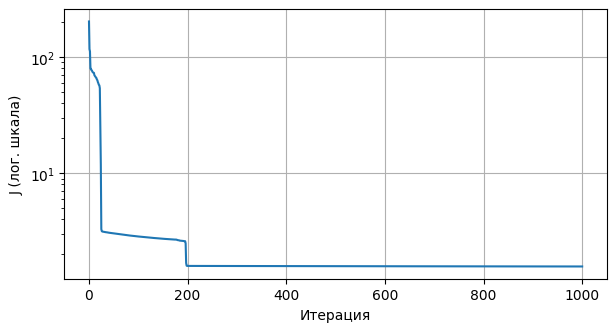

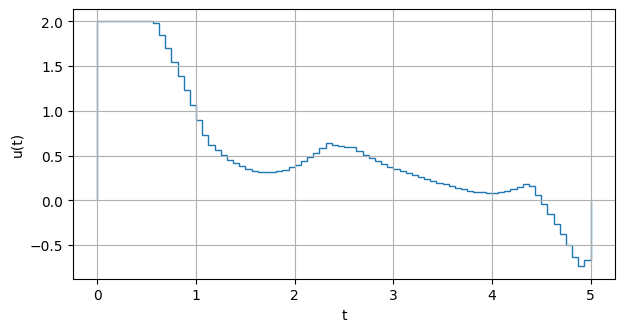

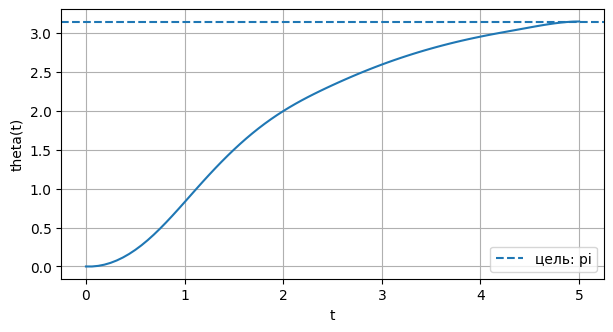

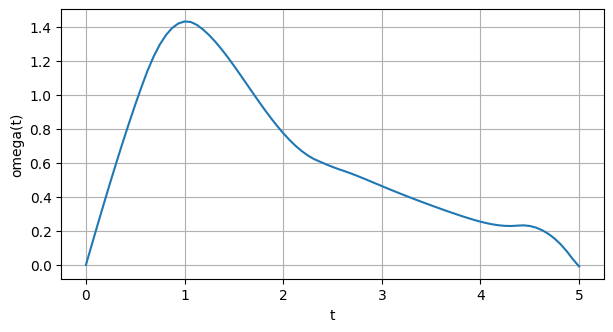

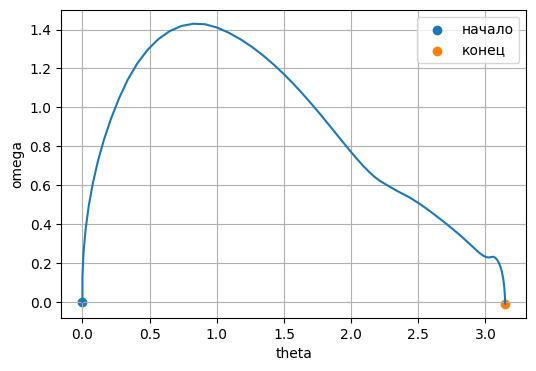

In [7]:
u0 = np.zeros(N)
# С большого пробного шага backtracking сам спускается до подходящего.
u_pg, history_pg, alpha_pg = projected_gradient_backtracking(u0, *params, alpha0=30)
x_pg = simulate_pendulum(u_pg, gamma)
t_edges = np.linspace(0, T, N + 1)
t = t_edges[:-1]

print(f"Начальное J = {history_pg[0]:.6f}")
print(f"После метода проекции J = {history_pg[-1]:.6f}")
print(f"Итераций: {len(alpha_pg)}")
print(f"Принятый шаг alpha: от {alpha_pg.min():.6f} до {alpha_pg.max():.3f}")
print(f"Конечное состояние: theta = {x_pg[-1, 0]:.6f}, omega = {x_pg[-1, 1]:.6f}")

plt.figure(figsize=(7, 3.5))
plt.semilogy(history_pg)
plt.xlabel("Итерация")
plt.ylabel("J (лог. шкала)")
plt.grid()
plt.show()

plt.figure(figsize=(7, 3.5))
plt.stairs(u_pg, t_edges)
plt.xlabel("t")
plt.ylabel("u(t)")
plt.grid()
plt.show()

plt.figure(figsize=(7, 3.5))
plt.plot(t_edges, x_pg[:, 0])
plt.axhline(np.pi, linestyle="--", label="цель: pi")
plt.xlabel("t")
plt.ylabel("theta(t)")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(7, 3.5))
plt.plot(t_edges, x_pg[:, 1])
plt.xlabel("t")
plt.ylabel("omega(t)")
plt.grid()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(x_pg[:, 0], x_pg[:, 1])
plt.scatter(x_pg[0, 0], x_pg[0, 1], label="начало")
plt.scatter(x_pg[-1, 0], x_pg[-1, 1], label="конец")
plt.xlabel("theta")
plt.ylabel("omega")
plt.grid()
plt.legend()
plt.show()

**Наблюдение:** значение $J$ убывало, но за 1000 итераций метод остановился по ограничению на число шагов. Поэтому считать его полностью сошедшимся пока нельзя.

# 5. Сравнение с L-BFGS-B

Решаем ту же дискретную задачу с ограничениями $-2\le u_k\le2$.
Градиент передаём в `jac`. Ошибку в конце считаем как
$\|x_N-(\pi,0)\|_2$, расход управления — как $h\sum u_k^2$.

,метод,J,ошибка в конце,расход управления,итераций
0,Проекционный градиент,1.574911,0.010387,4.001822,1000
1,L-BFGS-B,1.526822,0.001339,4.173940,151


L-BFGS-B: success = True
Максимальное отличие управлений: 0.635549


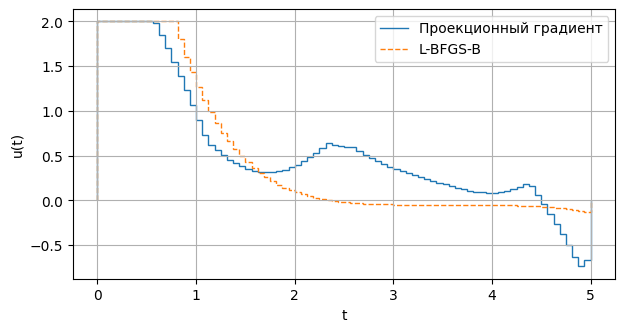

In [8]:
res = minimize(
    objective_pendulum, np.zeros(N), args=params,
    jac=adjoint_gradient_pendulum,
    method="L-BFGS-B",
    bounds=[(-u_max, u_max)] * N,
    options={"maxiter": 1000, "ftol": 1e-12, "gtol": 1e-8},
)

x_lb = simulate_pendulum(res.x, gamma)
h = T / N
comparison = pd.DataFrame([
    {
        "метод": "Проекционный градиент",
        "J": history_pg[-1],
        "ошибка в конце": np.linalg.norm(x_pg[-1] - x_target),
        "расход управления": h * np.sum(u_pg**2),
        "итераций": len(alpha_pg),
    },
    {
        "метод": "L-BFGS-B",
        "J": res.fun,
        "ошибка в конце": np.linalg.norm(x_lb[-1] - x_target),
        "расход управления": h * np.sum(res.x**2),
        "итераций": res.nit,
    },
])
display(comparison.round(6))
print("L-BFGS-B: success =", res.success)
print(f"Максимальное отличие управлений: {np.max(np.abs(u_pg - res.x)):.6f}")

plt.figure(figsize=(7, 3.5))
plt.stairs(u_pg, t_edges, label="Проекционный градиент")
plt.stairs(res.x, t_edges, label="L-BFGS-B", linestyle="--")
plt.xlabel("t")
plt.ylabel("u(t)")
plt.grid()
plt.legend()
plt.show()

**Сравнение:** `L-BFGS-B` получил меньшее значение $J$ и меньшую ошибку в конечной точке.
Проекционный градиент уменьшал функционал на каждом шаге, но за 1000 итераций
не дошёл до того же результата. Оба метода сначала используют управление на верхней
границе, а дальше их управления заметно расходятся.

# 6. Индивидуальный эксперимент — вариант B: Штраф за отклонение угла

Меняем $q_\\theta$: 0, 0.05, 0.2, 0.5.

**Прогноз:** Ожидаю, что при большем штрафе за угол управление будет сильнее: нужно раньше приблизиться к положению $\theta=\pi$.

,q_theta,J,terminal error,control effort,max |u|,success
0,0.00,0.272450,0.008303,3.022244,1.099312,True
1,0.05,0.941543,0.002772,3.765288,2.000000,True
2,0.20,2.656021,0.000195,4.752432,2.000000,True
3,0.50,5.957445,0.000587,5.795720,2.000000,True


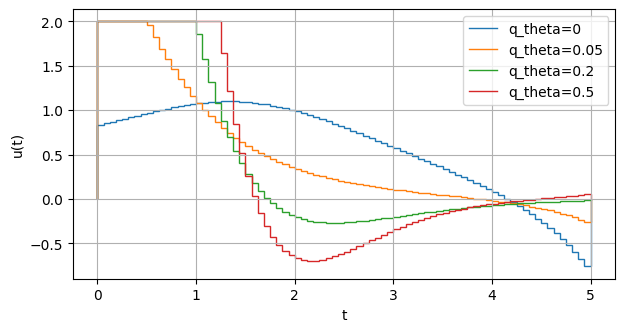

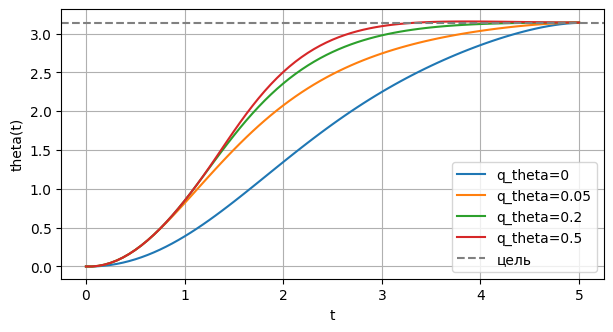

In [9]:
q_values = [0, 0.05, 0.2, 0.5]
results = []
controls = {}
trajectories = {}

for q in q_values:
    args = (gamma, q, q_omega, lam)
    r = minimize(
        objective_pendulum, np.zeros(N), args=args,
        jac=adjoint_gradient_pendulum, method="L-BFGS-B",
        bounds=[(-u_max, u_max)] * N,
        options={"maxiter": 1000, "ftol": 1e-12, "gtol": 1e-8},
    )
    x = simulate_pendulum(r.x, args[0])
    controls[q] = r.x
    trajectories[q] = x
    results.append({
        "q_theta": q,
        "J": r.fun,
        "terminal error": np.linalg.norm(x[-1] - x_target),
        "control effort": h * np.sum(r.x**2),
        "max |u|": np.max(np.abs(r.x)),
        "success": r.success,
    })

experiment = pd.DataFrame(results)
display(experiment.round(6))

plt.figure(figsize=(7, 3.5))
for value, u in controls.items():
    plt.stairs(u, t_edges, label=f"q_theta={value}")
plt.xlabel("t")
plt.ylabel("u(t)")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(7, 3.5))
for value, x in trajectories.items():
    plt.plot(t_edges, x[:, 0], label=f"q_theta={value}")
plt.axhline(np.pi, color="gray", linestyle="--", label="цель")
plt.xlabel("t")
plt.ylabel("theta(t)")
plt.grid()
plt.legend()
plt.show()

При росте $q_\theta$ от 0 до 0.5 расход управления вырос с **3.0222** до **5.7957**. Максимум $|u|$ изменился с **1.0993** до **2**. По графику видно, что при большем штрафе угол быстрее приближается к $\pi$. Само значение $J$ в этих опытах напрямую сравнивать нельзя, потому что мы меняли функционал. В целом результат совпал с прогнозом.

# Итог

Проверка градиента прошла: минимальная относительная ошибка около $1.31\cdot10^{-11}$.
По сравнению с задачей из `sem5` в сопряжённой системе появился множитель $(1-h\gamma)$ и добавились производные интегрального штрафа по состоянию.
За 1000 итераций метод проекции уменьшил функционал до $J=1.574911$, но не достиг того же результата, что `L-BFGS-B`.
`L-BFGS-B` получил $J=1.526822$ за 151 итерацию.
Оба управления сначала доходят до верхнего ограничения, но потом отличаются, максимальная разница — $0.63555$.
При росте $q_\theta$ от 0 до 0.5 расход управления вырос с 3.0222 до 5.7957.
По графику видно, что при большем штрафе маятник раньше приближается к углу $\pi$.
Это совпало с прогнозом: чтобы раньше попасть в нужное положение, приходится сильнее управлять маятником.